# Proyecto 3: Mejorando algoritmos con CUDA

**CC3069 Computación Paralela y Distribuida, UVG.** Adrián González (23152), Fernando Mendoza (19644) y Hansel López (19026).

Partimos del Lab 3 de Data Science: una MobileNetV3-Small que reconoce las 29 señas del alfabeto ASL
(26 letras, `del`, `nothing` y `space`) a partir de fotos de 200 × 200. En CPU, su entrenamiento completo
tomó 3.7 horas. En este notebook mostramos la versión original y la nueva, con la separación que pide el
enunciado: la **preparación de las imágenes en los núcleos del CPU** (fase 1) y **la transformación de
entrada y el entrenamiento en la GPU con CUDA** (fase 2).

El código no se reimplementa aquí: todo se importa del paquete `asl_cuda` (`src/asl_cuda/`), que es el
mismo que usan los scripts de medición. Las celdas de GPU se saltan solas si no hay una GPU NVIDIA.

| Integrante | Parte |
|---|---|
| Fernando Mendoza | Análisis del Lab 3, diseño del algoritmo paralelo, kernel CUDA e implementación |
| Hansel | Medición de la versión secuencial y CPU, pruebas con datos nuevos, notebook e informe |
| Adrian | Corridas en GPU, entrenamiento final, evidencia de hardware y demo |

## 1. Entorno

Primero registramos en qué hardware corre el notebook. `asl_cuda.envinfo` es lo mismo que guarda cada
corrida en `environment.json`.

In [1]:
import inspect
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

from asl_cuda.constants import CLASSES, ROOT
from asl_cuda.envinfo import environment

GPU = torch.cuda.is_available()
device = torch.device("cuda" if GPU else "cpu")
env = environment(device)
print(f"CPU: {env['cpu']} | núcleos físicos {env['physical_cores']}, lógicos {env['logical_cores']} | RAM {env['ram_gb']} GB")
print(f"GPU: {env['gpu'].get('name', 'no disponible')}")
print("Versiones:", {k: v for k, v in env["packages"].items() if v})

CPU: AMD Ryzen 5 7235HS | núcleos físicos 4, lógicos 8 | RAM 15.7 GB
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Versiones: {'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'numba': '0.68.1', 'numba-cuda': '0.30.4', 'numpy': '2.4.6', 'pillow': '13.0.0'}


In [2]:
if GPU:
    !nvidia-smi

Wed Nov 18 15:17:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.66                 Driver Version: 591.66         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   39C    P8              3W /   95W |     736MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Datos y partición

El dataset `grassknoted/asl-alphabet` tiene 3,000 frames de video por clase. Frames vecinos son casi
idénticos, así que la partición no es al azar: se agrupan en ventanas de 100 frames y cada ventana va
completa a una sola partición (entrenamiento, validación o prueba). `asl-cuda prep` también comprueba con
SHA-256 que no haya archivos idénticos entre particiones.

In [3]:
from asl_cuda.config import load_data_config, load_train_config

dcfg = load_data_config(ROOT / "configs/data.yaml")
tcfg = load_train_config(ROOT / "configs/train.yaml")
cache_dir = dcfg.path("cache_dir")
manifest = pd.read_csv(cache_dir / "manifest.csv")
conteos = manifest.groupby("split").agg(imagenes=("path", "size"), ventanas=("window", "nunique"))
conteos["por_clase"] = conteos["imagenes"] // len(CLASSES)
conteos

,imagenes,ventanas,por_clase
split,,,
test,11600,4,400
train,43500,15,1500
validation,11600,4,400


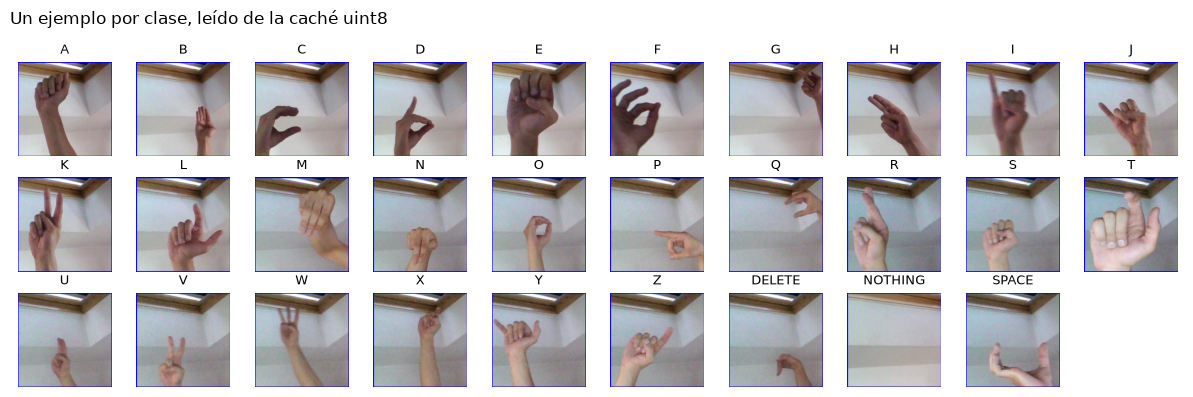

In [4]:
from asl_cuda.prep import load_split

train_data = load_split(cache_dir, "train", dcfg.cache_size)
primeros = [int(np.flatnonzero(train_data.labels == c)[len(np.flatnonzero(train_data.labels == c)) // 2]) for c in range(len(CLASSES))]
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for ax, c, i in zip(axes.flat, range(len(CLASSES)), primeros):
    ax.imshow(train_data.images[i])
    ax.set_title(CLASSES[c], fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Un ejemplo por clase, leído de la caché uint8", x=0.01, ha="left")
plt.tight_layout()

## 3. Versión original (secuencial)

Copiamos del Lab 3 la parte que se ejecuta en cada época: el `Dataset` que abre y decodifica cada JPEG y
la cadena de transformaciones de torchvision con PIL. El único cambio es que el ciclo de entrenamiento
mide por separado el tiempo de datos y el de cálculo.

In [5]:
from asl_cuda import secuencial

print(inspect.getsource(secuencial.lab3_transform))
print(inspect.getsource(secuencial.FileDataset))

def lab3_transform(size: int, augment: bool) -> transforms.Compose:
    """Misma secuencia de `robust_transform` del Lab 3.

    Único cambio: las dos lambdas del original se reemplazaron por una función
    con nombre, porque en Windows los procesos del DataLoader se crean con
    spawn y una lambda no se puede serializar.
    """
    prefix: list[Any] = [transforms.Lambda(_exif_rgb)]
    if augment:
        visual: list[Any] = [
            transforms.RandomResizedCrop(size, scale=(0.70, 1.0), ratio=(0.90, 1.10)),
            transforms.RandomAffine(10, translate=(0.07, 0.07), scale=(0.93, 1.07)),
            transforms.ColorJitter(0.20, 0.20, 0.12, 0.02),
            transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 1.0))], p=0.10),
            transforms.RandomPerspective(distortion_scale=0.12, p=0.12),
        ]
    else:
        visual = [transforms.Resize(size + 32), transforms.CenterCrop(size)]
    suffix: list[Any] = [transforms.ToTensor(), transforms.Normalize(IM

Medimos dos lotes de 64 imágenes en un solo hilo y sin procesos auxiliares, que es la versión secuencial
de referencia. Una medición de dos lotes es solo ilustrativa; las tablas oficiales (sección 7) usan 1,160
imágenes, calentamiento y repeticiones.

In [6]:
from torch import nn

from asl_cuda.manifest import absolute_paths, subsample
from asl_cuda.model import build_model

muestra = subsample(manifest[manifest["split"] == "train"], 40).reset_index(drop=True)
rutas = absolute_paths(muestra)

hilos_antes = torch.get_num_threads()
torch.set_num_threads(1)
loader = secuencial.make_loader(muestra, rutas, tcfg.image_size, 64, augment=True, workers=0, seed=0, shuffle=True)
modelo = build_model(tcfg.architecture, pretrained=False)
optim = torch.optim.AdamW(modelo.parameters(), lr=1e-4)
r = secuencial.run_epoch(modelo, loader, optim, nn.CrossEntropyLoss(), clip=1.0, max_batches=2)
torch.set_num_threads(hilos_antes)

print(f"{r['images']} imágenes en {r['seconds']:.2f} s ({r['images'] / r['seconds']:.1f} img/s)")
print(f"  datos (abrir, decodificar, transformar): {r['data_seconds']:.2f} s ({100 * r['data_seconds'] / r['seconds']:.0f} %)")
print(f"  red (forward, backward, AdamW):          {r['compute_seconds']:.2f} s ({100 * r['compute_seconds'] / r['seconds']:.0f} %)")

128 imágenes en 7.51 s (17.0 img/s)
  datos (abrir, decodificar, transformar): 1.22 s (16 %)
  red (forward, backward, AdamW):          6.29 s (84 %)


## 4. Fase 1 · Preparación de imágenes en el CPU

Leer un archivo y decodificar un JPEG necesita el sistema de archivos y libjpeg, y la decodificación
Huffman es secuencial dentro de cada archivo. Lo que sí es paralelo es que los archivos son independientes
entre sí: `decode_to_npy` reparte bloques de rutas entre procesos y cada proceso escribe sus imágenes
directamente en un arreglo `uint8` en disco abierto con *memory map*. Esto se hace **una sola vez**; el
Lab 3 lo repetía en cada época (1,911,100 decodificaciones para 55,100 archivos).

Usamos procesos y no hilos por el GIL de Python (sección 2.4 del informe).

In [7]:
import os
import tempfile

from asl_cuda.prep import decode_to_npy

muestra_prep = subsample(manifest[manifest["split"] == "train"], 200)
rutas_prep = absolute_paths(muestra_prep)

tiempos = {}
with tempfile.TemporaryDirectory() as tmp:
    # una pasada de calentamiento para que los JPEG ya estén en la caché del sistema operativo
    decode_to_npy(rutas_prep, Path(tmp) / "calentamiento.npy", dcfg.cache_size, 0)
    for workers in (1, 0):  # 0 = todos los núcleos lógicos
        t = time.perf_counter()
        stats, _ = decode_to_npy(rutas_prep, Path(tmp) / f"prueba_{workers}.npy", dcfg.cache_size, workers)
        tiempos[stats.workers] = time.perf_counter() - t

base = tiempos[1]
for procesos, segundos in tiempos.items():
    print(f"{procesos:>2} proceso(s): {segundos:.2f} s, {len(rutas_prep) / segundos:,.0f} img/s, speedup {base / segundos:.2f}")

 1 proceso(s): 5.67 s, 1,023 img/s, speedup 1.00
 8 proceso(s): 1.90 s, 3,048 img/s, speedup 2.98


## 5. Fase 2 · Kernel CUDA de entrada

La transformación de entrada (recorte, rotación, zoom, perspectiva, color, normalización y borrado) se
expresa como una homografía y 7 números más por imagen. Con eso cada píxel de salida es independiente:
**un hilo por píxel**, bloques de 16 × 16 = 256 hilos (8 warps) y un grid de 14 × 14 × B, donde la
tercera dimensión es la imagen dentro del lote.

La misma función por píxel (`_pixel`) se compila como función de dispositivo CUDA y como función de CPU
con `numba.njit(parallel=True)`.

In [8]:
from asl_cuda import augment

print(inspect.getsource(augment._pixel))
print(inspect.getsource(augment._warp_kernel))
grid, bloque = augment.grid_for(64, tcfg.image_size, tcfg.image_size, (16, 16))
print(f"Lote de 64: grid {grid}, bloque {bloque} -> {np.prod(grid):,} bloques, {np.prod(grid) * np.prod(bloque):,} hilos")

def _pixel(src, b, x, y, params, mean, std, out):
    # params[b] = [h0..h8, brillo, contraste, saturación, ex0, ey0, ex1, ey1]
    fx = np.float32(x) + HALF
    fy = np.float32(y) + HALF
    w = params[b, 6] * fx + params[b, 7] * fy + params[b, 8]
    sx = (params[b, 0] * fx + params[b, 1] * fy + params[b, 2]) / w - HALF
    sy = (params[b, 3] * fx + params[b, 4] * fy + params[b, 5]) / w - HALF

    hs = src.shape[1]
    ws = src.shape[2]
    x0 = int(math.floor(sx))
    y0 = int(math.floor(sy))
    ax = sx - np.float32(x0)
    ay = sy - np.float32(y0)
    xa = min(max(x0, 0), ws - 1)
    xb = min(max(x0 + 1, 0), ws - 1)
    ya = min(max(y0, 0), hs - 1)
    yb = min(max(y0 + 1, 0), hs - 1)
    w00 = (F1 - ax) * (F1 - ay)
    w01 = ax * (F1 - ay)
    w10 = (F1 - ax) * ay
    w11 = ax * ay

    r = (w00 * np.float32(src[b, ya, xa, 0]) + w01 * np.float32(src[b, ya, xb, 0])
         + w10 * np.float32(src[b, yb, xa, 0]) + w11 * np.float32(src[b, yb, xb, 0])) * INV255
    g = (w00 * np.flo

Comprobamos que el kernel calcula lo mismo que una implementación NumPy independiente, y en GPU que
coincide con ella dentro del error de redondeo de float32.

In [9]:
rng = np.random.default_rng(0)
lote = train_data.images[rng.choice(len(train_data), 16, replace=False)]
params = augment.sample_params(rng, len(lote), dcfg.cache_size, tcfg.image_size, tcfg.augment, train=True).packed()

referencia = augment.warp_numpy(lote, params, tcfg.image_size)
salida_cpu = augment.warp_cpu(lote, params, np.empty_like(referencia))
print(f"Numba CPU vs NumPy: diferencia máxima {np.abs(salida_cpu - referencia).max():.2e}")
print(f"(valores normalizados entre {referencia.min():.2f} y {referencia.max():.2f}; la diferencia es redondeo de float32)")

if GPU:
    from numba import cuda

    d_out = cuda.device_array(referencia.shape, np.float32)
    augment.launch_warp(cuda.to_device(lote), cuda.to_device(params), cuda.to_device(augment.IMAGENET_MEAN),
                        cuda.to_device(augment.IMAGENET_STD), d_out, (16, 16))
    salida_gpu = d_out.copy_to_host()
    print(f"CUDA vs NumPy:      diferencia máxima {np.abs(salida_gpu - referencia).max():.2e}")

Numba CPU vs NumPy: diferencia máxima 1.26e-04
(valores normalizados entre -2.12 y 2.64; la diferencia es redondeo de float32)


CUDA vs NumPy:      diferencia máxima 8.09e-05


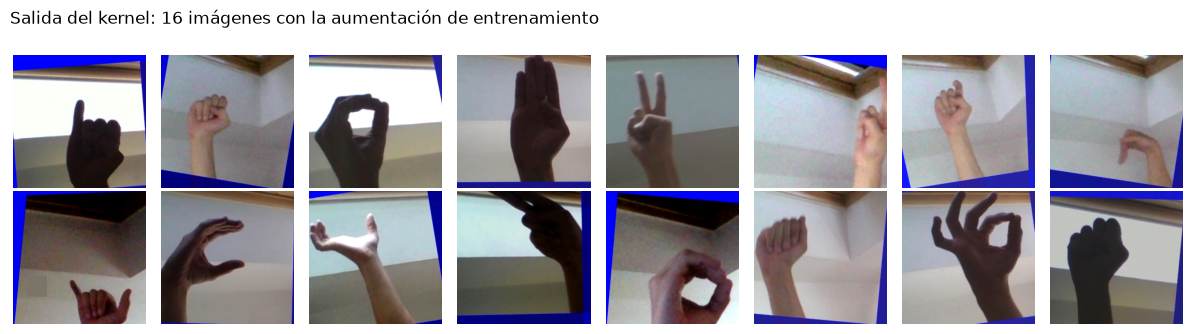

In [10]:
vista = salida_gpu if GPU else salida_cpu
img = vista.transpose(0, 2, 3, 1) * augment.IMAGENET_STD + augment.IMAGENET_MEAN
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, im in zip(axes.flat, img):
    ax.imshow(np.clip(im, 0, 1))
    ax.axis("off")
fig.suptitle("Salida del kernel: 16 imágenes con la aumentación de entrenamiento", x=0.01, ha="left")
plt.tight_layout()

## 6. Fase 2 · Entrenamiento en la GPU

`CudaFeeder` (`feeders.py`) arma cada lote en el CPU copiando 64 imágenes `uint8` de la caché a un buffer
*pinned*, lo copia a la GPU de forma asíncrona y lanza el kernel en el mismo stream que PyTorch; el
tensor resultante ya está en la GPU cuando empieza el forward. Con dos buffers alternados, el CPU prepara
el lote siguiente mientras la GPU entrena con el actual. Este es el paso de entrenamiento:

In [11]:
from asl_cuda import train

print(inspect.getsource(train.train_step))

def train_step(model, images, labels, loss_fn, optimizer, scaler, device, amp: bool, clip: float):
    optimizer.zero_grad(set_to_none=True)
    with autocast(device, amp):
        logits = model(images)
        loss = loss_fn(logits, labels)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), clip)
    scaler.step(optimizer)
    scaler.update()
    return logits, loss



Para que se vea correr, entrenamos 10 lotes con el mismo feeder que usa el entrenamiento completo
(en GPU si está disponible; si no, con el kernel de Numba en CPU).

In [12]:
from asl_cuda.model import set_trainable

train.configure_backend(device, tcfg)
amp = tcfg.cuda.amp and GPU
modelo = build_model(tcfg.architecture, pretrained=False).to(device)
if GPU:
    modelo = modelo.to(memory_format=torch.channels_last)
set_trainable(modelo, 4)
optim = torch.optim.AdamW((p for p in modelo.parameters() if p.requires_grad), lr=3e-4)
scaler = torch.amp.GradScaler(device.type, enabled=amp)
feeder = train.make_feeder(train_data, tcfg, device, train=True, limit=640)

t = time.perf_counter()
for paso, (x, y) in enumerate(feeder, 1):
    _, perdida = train.train_step(modelo, x, y, nn.CrossEntropyLoss(), optim, scaler, device, amp, 1.0)
if GPU:
    torch.cuda.synchronize()
segundos = time.perf_counter() - t
print(f"{paso} lotes en {segundos:.2f} s en {device} ({640 / segundos:.0f} img/s, incluye calentamiento), pérdida final {perdida.item():.3f}")
print(f"Tiempo armando lotes en el CPU: {feeder.data_wait:.2f} s")

10 lotes en 25.66 s en cuda (25 img/s, incluye calentamiento), pérdida final 1.572
Tiempo armando lotes en el CPU: 0.40 s


Esta celda solo muestra que el ciclo de entrenamiento corre de punta a punta con el kernel en la GPU; no es una medición.
Los 25 img/s incluyen el calentamiento (cuDNN prueba algoritmos en el primer lote) y que aquí el modelo se pasa a
`channels_last`, como estaba en el diseño. La medición controlada de la sección siguiente (`train.md`) mostró que con
esta red ese formato hace el paso casi 8 veces más lento, por eso la configuración final lo desactiva: sin él, el paso
de entrenamiento en la GPU procesa unas 2,700 imágenes por segundo.

## 7. Mediciones

Las mediciones oficiales vienen de `asl-cuda bench` en la laptop con GPU (CPU y GPU en la misma máquina,
para que el speedup tenga sentido). Aquí solo se cargan los resultados guardados en `results/`.

In [13]:
def buscar(condicion):
    for carpeta in sorted((ROOT / "results").glob("*")):
        if condicion(carpeta):
            return carpeta
    return None

oficial = buscar(lambda c: (c / "train" / "base-cuda" / "summary.json").exists())
referencias_cpu = [c for c in sorted((ROOT / "results").glob("*")) if (c / "bench" / "environment.json").exists()
                  and not json.loads((c / "bench" / "environment.json").read_text()).get("gpu", {}).get("available")]
print("Corrida oficial (GPU):", oficial.name if oficial else "todavía no está en results/")
print("Computadoras de referencia (solo CPU):", ", ".join(c.name for c in referencias_cpu) or "ninguna")


def tabla(carpeta, nombre, titulo):
    ruta = carpeta / "tablas" / f"{nombre}.md" if carpeta else None
    if ruta and ruta.exists():
        display(Markdown(f"**{titulo}** (`{ruta.relative_to(ROOT)}`)\n\n" + ruta.read_text(encoding="utf-8")))


def figura(carpeta, nombre, ancho=720):
    ruta = carpeta / "figuras" / f"{nombre}.png" if carpeta else None
    if ruta and ruta.exists():
        display(Image(filename=str(ruta), width=ancho))

Corrida oficial (GPU): adrian-rtx3050
Computadoras de referencia (solo CPU): fernando-ryzen-ai9, hansel-apple-m3


**Resumen por fase** (`results\adrian-rtx3050\tablas\fases.md`)

| Fase | Secuencial (ms/img) | Mejor variante CPU | CPU (ms/img) | Speedup CPU | GPU (ms/img) | Speedup GPU |
|---|---:|---|---:|---:|---:|---:|
| Decodificación (fase 1) | 0.593 | procesos=8 | 0.275 | 2.160 |  |  |
| Transformación de entrada | 4.011 | Numba CPU 8 hilos | 0.501 | 8.012 | 0.006 | 646.8 |
| Paso de entrenamiento | 13.8 | CPU 8 hilos | 7.137 | 1.928 | 0.371 | 37.1 |
| Inferencia por lotes | 5.178 | CPU 8 hilos lote 64 | 2.955 | 1.752 | 0.167 | 31.1 |
| Época completa | 17.9 | Híbrido CPU (caché + Numba CPU, 8 hilos) | 7.721 | 2.318 | 0.454 | 39.4 |


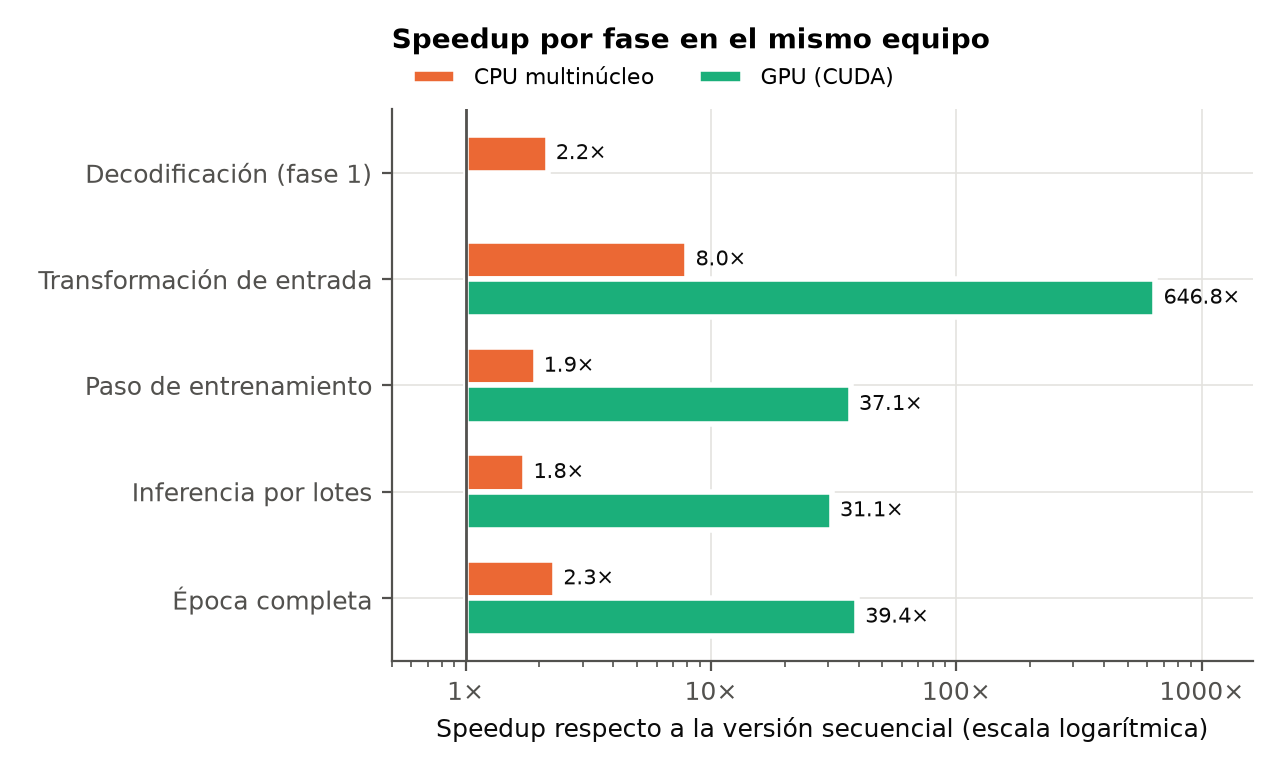

**Época completa** (`results\adrian-rtx3050\tablas\pipeline.md`)

| Variante | Imágenes | Tiempo medio (s) | Desv. est. (s) | CV (%) | Imágenes/s | Speedup |
|---|---:|---:|---:|---:|---:|---:|
| Lab 3 secuencial (0 workers, 1 hilo) | 1,160 | 20.8 | 0.231 | 1.114 | 55.9 | 1.000 |
| Lab 3 como se entregó (4 workers, 8 hilos) | 1,160 | 31.6 | 0.541 | 1.712 | 36.7 | 0.657 |
| Híbrido CPU (caché + Numba CPU, 8 hilos) | 1,160 | 8.956 | 0.046 | 0.515 | 129.5 | 2.318 |
| Híbrido GPU, aumentación en CPU | 1,160 | 1.313 | 0.133 | 10.1 | 883.3 | 15.8 |
| Híbrido GPU, kernel CUDA (propuesta) | 1,160 | 0.527 | 0.011 | 2.059 | 2,200.3 | 39.4 |


**Proyección del entrenamiento completo** (`results\adrian-rtx3050\tablas\proyeccion_entrenamiento.md`)

| Variante | Min por época | Horas totales | Speedup |
|---|---:|---:|---:|
| Lab 3 secuencial (0 workers, 1 hilo) | 13.0 | 3.028 | 1.000 |
| Lab 3 como se entregó (4 workers, 8 hilos) | 19.7 | 4.607 | 0.657 |
| Híbrido CPU (caché + Numba CPU, 8 hilos) | 5.598 | 1.327 | 2.283 |
| Híbrido GPU, aumentación en CPU | 0.821 | 0.212 | 14.3 |
| Híbrido GPU, kernel CUDA (propuesta) | 0.329 | 0.097 | 31.1 |

Proyección lineal a 43,500 imágenes por época y 14 épocas (presupuesto máximo de la receta). Las variantes híbridas incluyen una sola vez la fase 1 medida en este equipo (73 s).


In [14]:
tabla(oficial, "fases", "Resumen por fase")
figura(oficial, "speedup_fases")
tabla(oficial, "pipeline", "Época completa")
tabla(oficial, "proyeccion_entrenamiento", "Proyección del entrenamiento completo")

**Fase 1: decodificación en CPU** (`results\adrian-rtx3050\tablas\prep.md`)

| Variante | Procesos/hilos | Tiempo medio (s) | Desv. est. (s) | Imágenes/s | Speedup | Eficiencia | Karp-Flatt e |
|---|---:|---:|---:|---:|---:|---:|---:|
| secuencial | 1 | 3.439 | 0.126 | 1,686.4 | 1.000 | 1.000 |  |
| procesos=2 | 2 | 2.094 | 0.017 | 2,770.4 | 1.643 | 0.821 | 0.217 |
| procesos=4 | 4 | 1.642 | 0.013 | 3,532.2 | 2.095 | 0.524 | 0.303 |
| procesos=8 | 8 | 1.592 | 0.034 | 3,642.7 | 2.160 | 0.270 | 0.386 |
| hilos=4 (mismo código, GIL) | 4 | 1.910 | 0.023 | 3,037.3 | 1.801 | 0.450 |  |


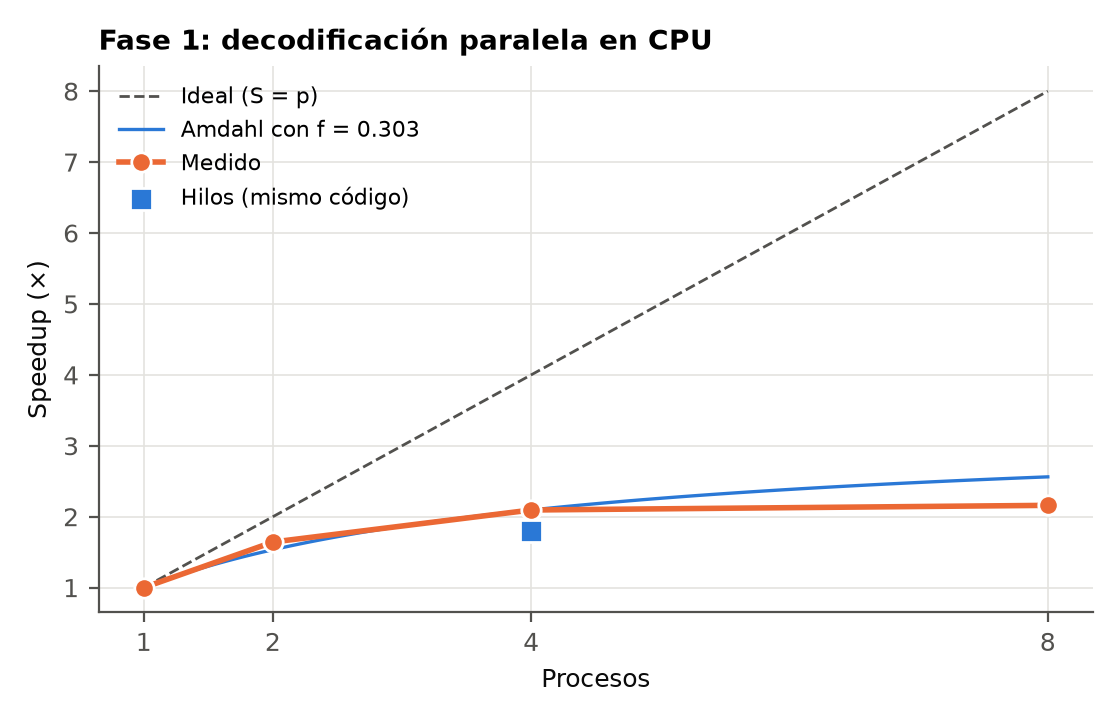

**Transformación de entrada** (`results\adrian-rtx3050\tablas\augment.md`)

| Variante | Imágenes | Tiempo medio (s) | Desv. est. (s) | CV (%) | Imágenes/s | Speedup |
|---|---:|---:|---:|---:|---:|---:|
| torchvision-PIL (Lab 3) | 1,160 | 4.653 | 0.054 | 1.164 | 249.3 | 1.000 |
| Numba CPU 1 hilo | 1,160 | 2.746 | 0.003 | 0.118 | 422.5 | 1.695 |
| Numba CPU 8 hilos | 1,160 | 0.581 | 0.060 | 10.4 | 1,997.4 | 8.012 |
| CUDA kernel 8x8 | 1,160 | 0.007 | 0.000 | 2.082 | 156,307.0 | 627.0 |
| CUDA kernel 16x8 | 1,160 | 0.007 | 0.000 | 0.557 | 160,920.3 | 645.5 |
| CUDA kernel 16x16 | 1,160 | 0.007 | 0.000 | 1.892 | 161,264.1 | 646.8 |
| CUDA kernel 32x8 | 1,160 | 0.007 | 0.000 | 2.318 | 160,673.5 | 644.5 |
| CUDA kernel 32x16 | 1,160 | 0.092 | 0.067 | 73.0 | 12,624.3 | 50.6 |
| CUDA kernel 32x32 | 1,160 | 0.008 | 0.000 | 1.723 | 137,212.2 | 550.4 |
| CUDA kernel + H2D + D2H | 1,160 | 0.107 | 0.002 | 2.214 | 10,886.9 | 43.7 |


**Kernel según hilos por bloque** (`results\adrian-rtx3050\tablas\kernel_bloques.md`)

| Bloque | Hilos/bloque | Tiempo medio (s) | ms por lote de 64 | Imágenes/s | CV (%) |
|---|---:|---:|---:|---:|---:|
| 8x8 | 64.0 | 0.007 | 0.391 | 156,307.0 | 2.082 |
| 16x8 | 128.0 | 0.007 | 0.379 | 160,920.3 | 0.557 |
| 16x16 | 256.0 | 0.007 | 0.379 | 161,264.1 | 1.892 |
| 32x8 | 256.0 | 0.007 | 0.380 | 160,673.5 | 2.318 |
| 32x16 | 512.0 | 0.092 | 4.836 | 12,624.3 | 73.0 |
| 32x32 | 1,024.0 | 0.008 | 0.445 | 137,212.2 | 1.723 |


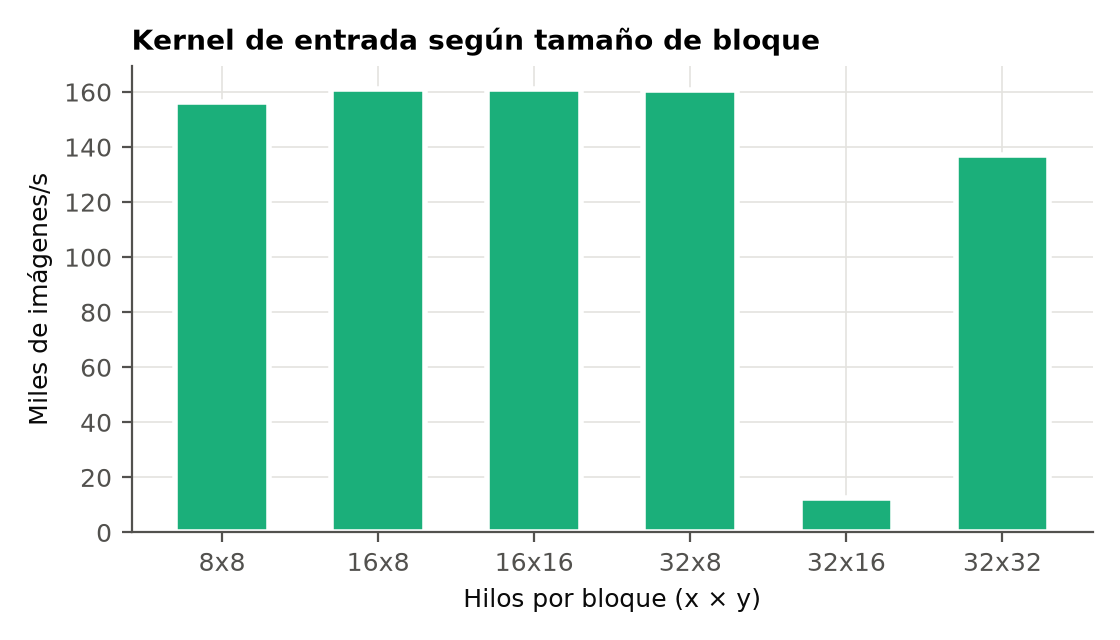

**Paso de entrenamiento** (`results\adrian-rtx3050\tablas\train.md`)

| Variante | Imágenes | Tiempo medio (s) | Desv. est. (s) | CV (%) | Imágenes/s | Speedup |
|---|---:|---:|---:|---:|---:|---:|
| CPU 1 hilo (secuencial) | 960 | 13.2 | 0.311 | 2.356 | 72.7 | 1.000 |
| CPU 8 hilos | 960 | 6.851 | 0.103 | 1.500 | 140.1 | 1.928 |
| GPU fp32 | 960 | 0.475 | 0.000 | 0.098 | 2,020.8 | 27.8 |
| GPU fp32 + cudnn.benchmark | 960 | 0.474 | 0.001 | 0.118 | 2,023.9 | 27.8 |
| GPU fp32 + channels_last | 960 | 3.777 | 0.003 | 0.073 | 254.2 | 3.497 |
| GPU AMP fp16 + channels_last | 960 | 3.254 | 0.006 | 0.176 | 295.0 | 4.058 |
| GPU AMP fp16 (propuesta) | 960 | 0.356 | 0.011 | 3.060 | 2,699.0 | 37.1 |


**Inferencia** (`results\adrian-rtx3050\tablas\inference.md`)

| Variante | Imágenes | Tiempo medio (s) | Desv. est. (s) | CV (%) | Imágenes/s | Speedup |
|---|---:|---:|---:|---:|---:|---:|
| CPU 1 hilo lote 64 | 320 | 1.657 | 0.015 | 0.891 | 193.1 | 1.000 |
| CPU 8 hilos lote 64 | 320 | 0.946 | 0.013 | 1.372 | 338.4 | 1.752 |
| GPU fp32 lote 64 | 1,280 | 0.353 | 0.001 | 0.212 | 3,625.6 | 18.8 |
| GPU AMP fp16 lote 64 | 1,280 | 0.213 | 0.006 | 2.763 | 5,998.4 | 31.1 |

| Variante | Latencia p50 (ms) | Latencia p95 (ms) | FPS equivalentes |
|---|---:|---:|---:|
| CPU 1 hilo 1 imagen | 6.186 | 6.927 | 161.7 |
| CPU 8 hilos 1 imagen | 8.845 | 10.9 | 113.5 |
| GPU fp32 1 imagen | 6.556 | 12.3 | 152.6 |
| GPU AMP fp16 1 imagen | 8.503 | 16.4 | 117.6 |


In [15]:
tabla(oficial, "prep", "Fase 1: decodificación en CPU")
figura(oficial, "prep_escalamiento", 560)
tabla(oficial, "augment", "Transformación de entrada")
tabla(oficial, "kernel_bloques", "Kernel según hilos por bloque")
figura(oficial, "kernel_bloques", 480)
tabla(oficial, "train", "Paso de entrenamiento")
tabla(oficial, "inference", "Inferencia")

**Entrenamientos completos** (`results\adrian-rtx3050\tablas\entrenamientos.md`)

| Corrida | Configuración | Épocas | s por época (train) | Imágenes/s | Espera por datos (%) | Total (min) | Macro F1 validación | Memoria GPU pico (MB) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| base-cpu-1epoca | CPU, 8 hilos | 1 | 241.9 | 179.9 | 13.3 | 4.781 | 0.942 |  |
| base-cuda | GPU, AMP, aumentación en GPU | 11 | 28.0 | 1,677.1 | 21.0 | 5.648 | 0.986 | 749.9 |
| base-cuda-aug-cpu | GPU, AMP, aumentación en CPU | 2 | 58.3 | 748.1 | 64.5 | 2.380 | 0.946 | 719.4 |
| robusto-cuda | GPU, AMP, aumentación en GPU | 14 | 27.8 | 1,662.8 | 10.8 | 7.080 | 0.994 | 749.9 |


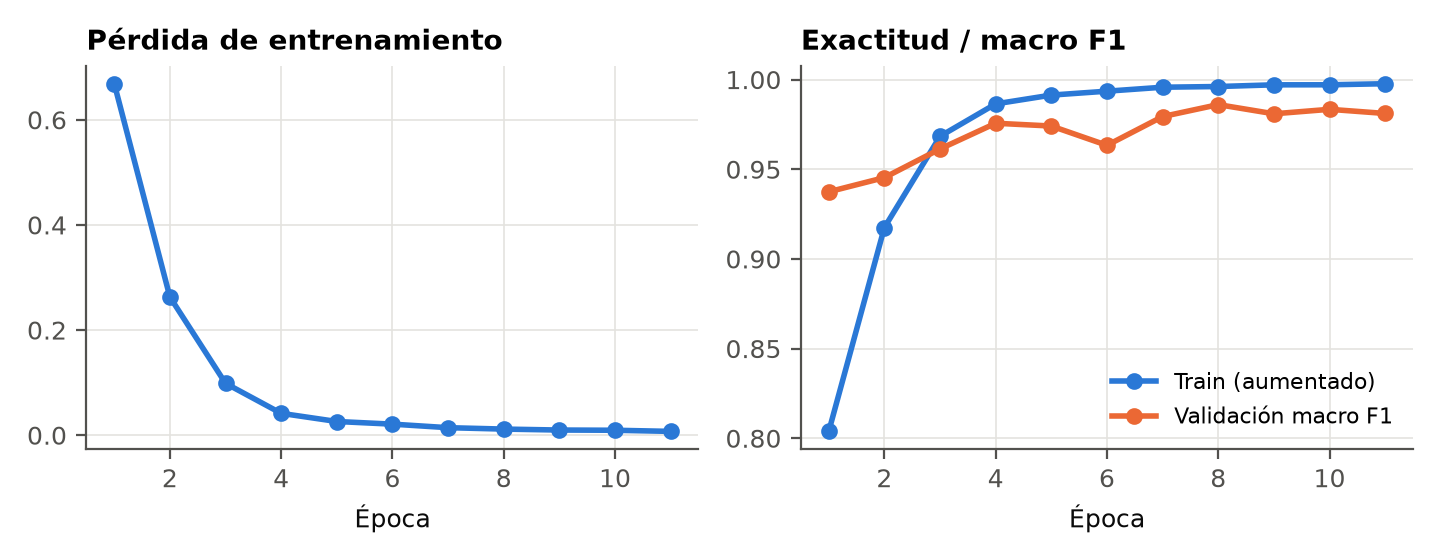

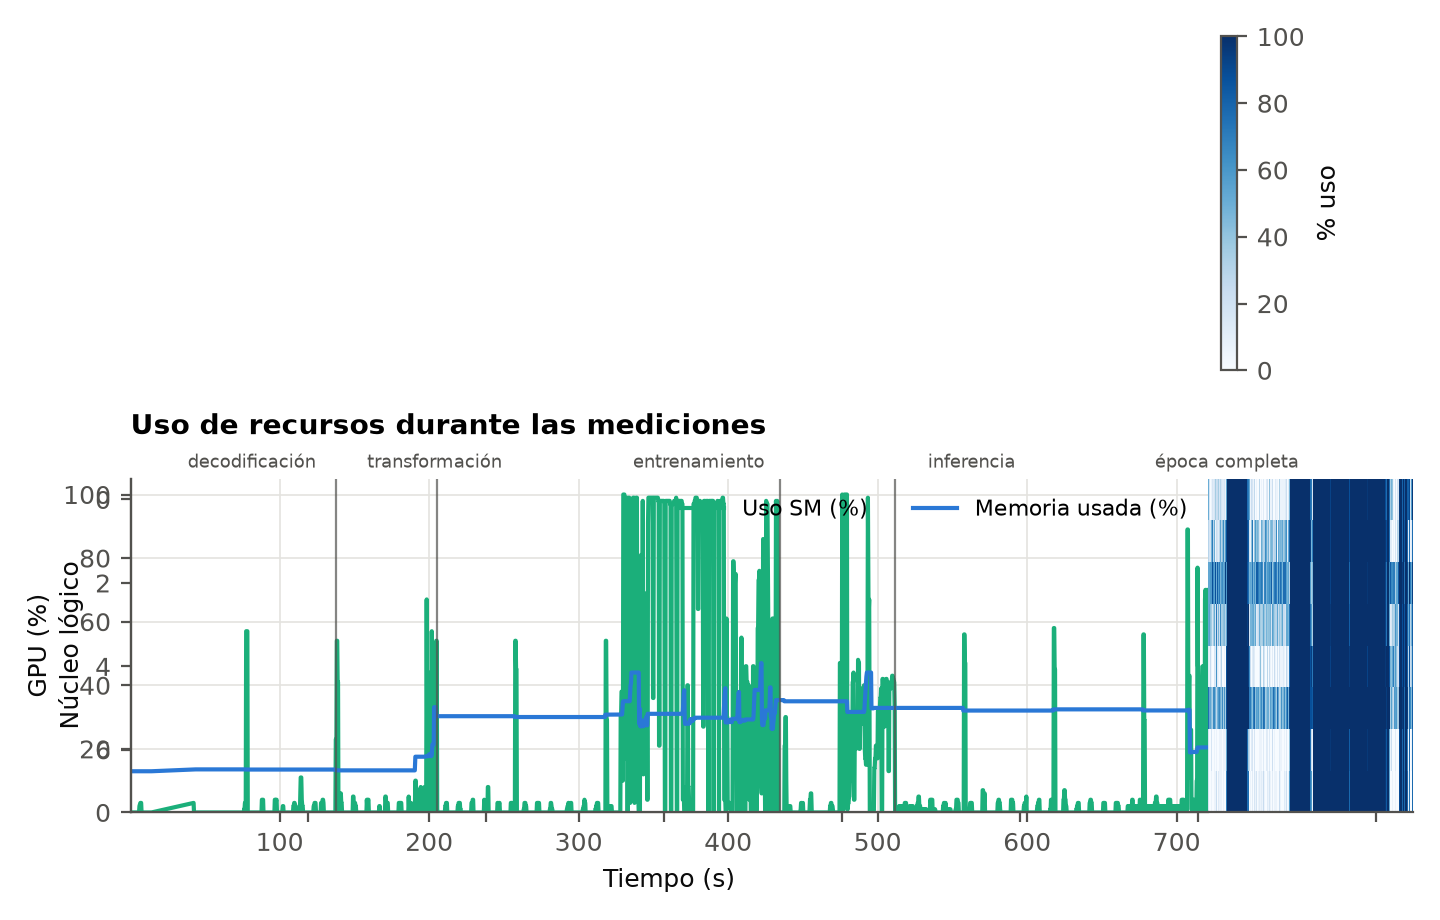

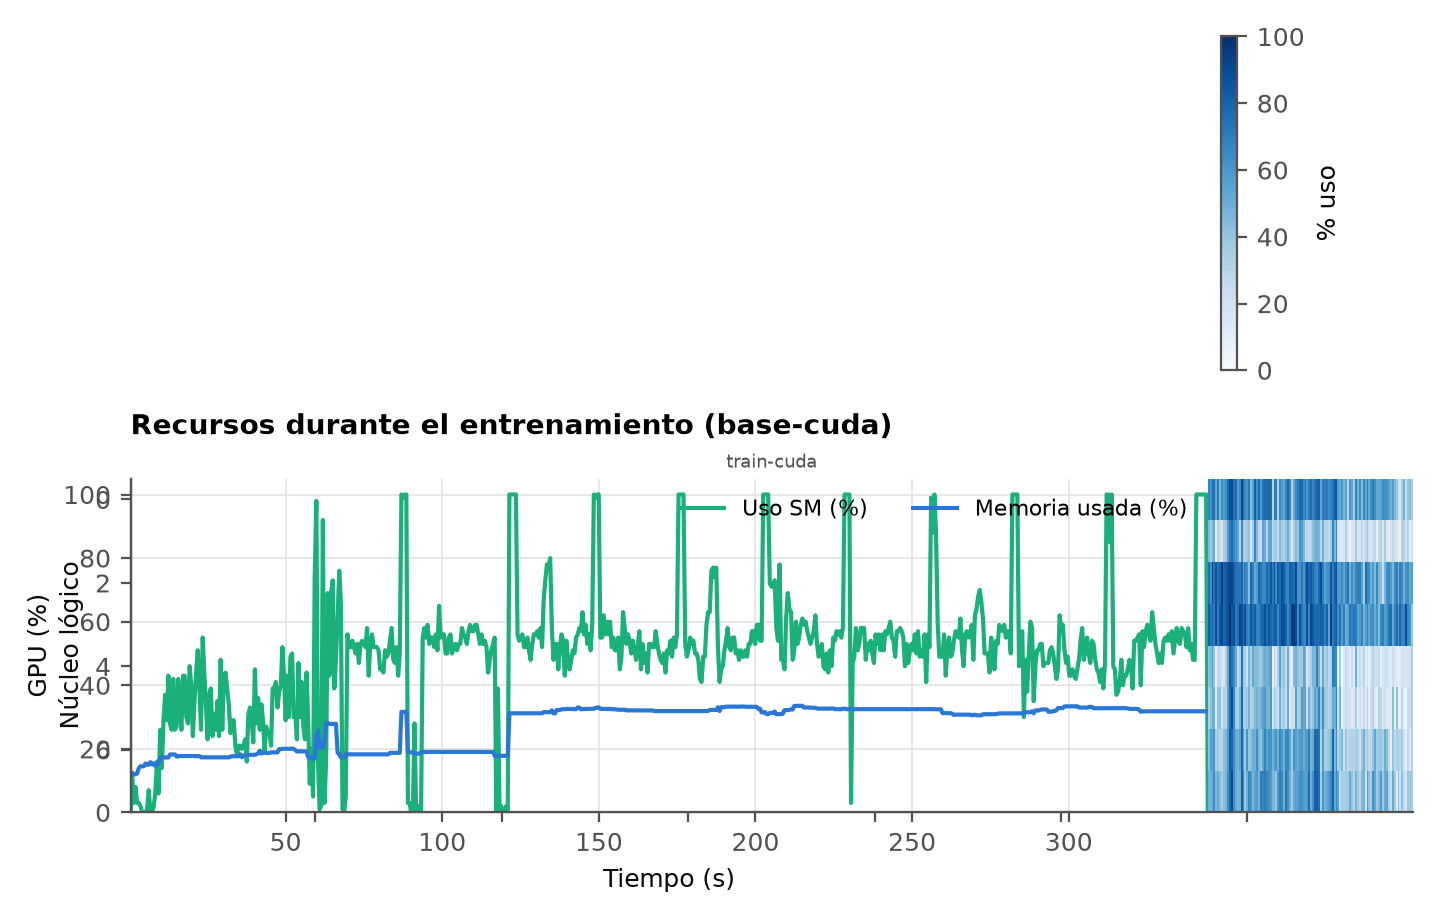

In [16]:
tabla(oficial, "entrenamientos", "Entrenamientos completos")
figura(oficial, "entrenamiento_base-cuda")
figura(oficial, "monitor_bench")
figura(oficial, "monitor_base-cuda")

Las computadoras sin GPU sirven para ver cómo cambia el escalamiento en CPU con otra arquitectura.

**Resumen por fase en fernando-ryzen-ai9** (`results\fernando-ryzen-ai9\tablas\fases.md`)

| Fase | Secuencial (ms/img) | Mejor variante CPU | CPU (ms/img) | Speedup CPU | GPU (ms/img) | Speedup GPU |
|---|---:|---|---:|---:|---:|---:|
| Decodificación (fase 1) | 0.593 | procesos=8 | 0.151 | 3.919 |  |  |
| Transformación de entrada | 5.036 | Numba CPU 20 hilos | 0.404 | 12.5 |  |  |
| Paso de entrenamiento | 12.2 | CPU 20 hilos | 8.399 | 1.450 |  |  |
| Inferencia por lotes | 9.112 | CPU 20 hilos lote 64 | 4.004 | 2.276 |  |  |
| Época completa | 22.3 | Híbrido CPU (caché + Numba CPU, 20 hilos) | 8.104 | 2.748 |  |  |


**Decodificación en fernando-ryzen-ai9** (`results\fernando-ryzen-ai9\tablas\prep.md`)

| Variante | Procesos/hilos | Tiempo medio (s) | Desv. est. (s) | Imágenes/s | Speedup | Eficiencia | Karp-Flatt e |
|---|---:|---:|---:|---:|---:|---:|---:|
| secuencial | 1 | 3.439 | 0.202 | 1,686.5 | 1.000 | 1.000 |  |
| procesos=2 | 2 | 1.814 | 0.106 | 3,197.3 | 1.896 | 0.948 | 0.055 |
| procesos=4 | 4 | 1.141 | 0.114 | 5,085.1 | 3.015 | 0.754 | 0.109 |
| procesos=8 | 8 | 0.878 | 0.081 | 6,608.7 | 3.919 | 0.490 | 0.149 |
| procesos=20 | 20 | 1.264 | 0.074 | 4,589.0 | 2.721 | 0.136 | 0.334 |
| hilos=10 (mismo código, GIL) | 10 | 6.743 | 0.085 | 860.2 | 0.510 | 0.051 |  |


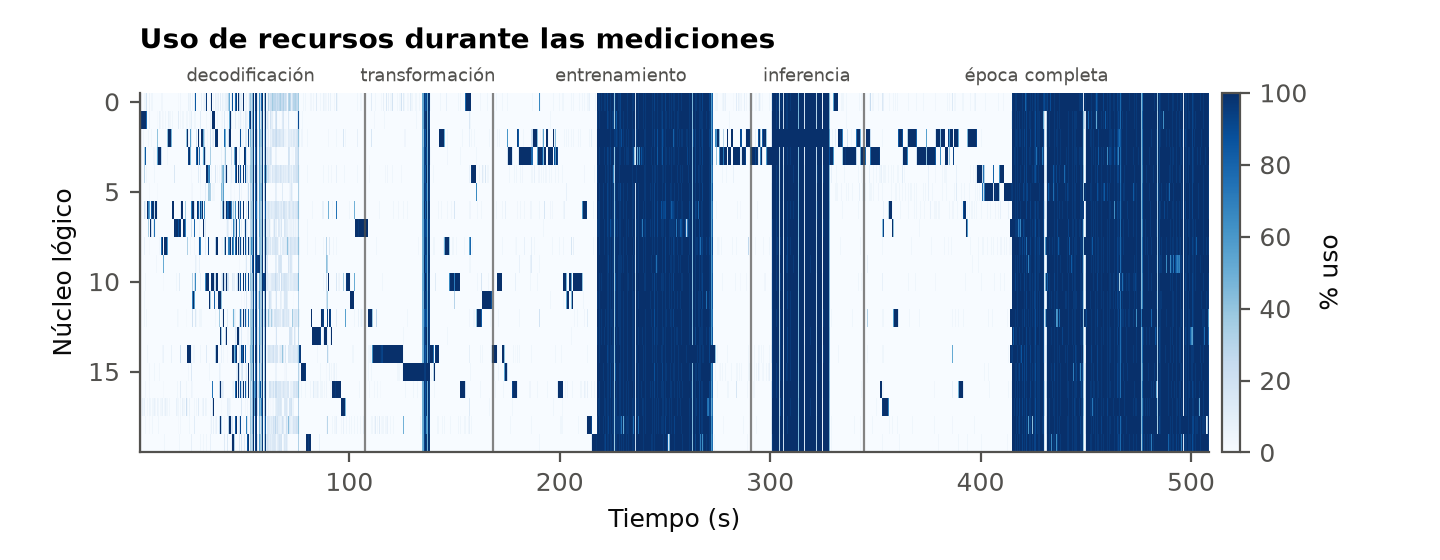

**Resumen por fase en hansel-apple-m3** (`results\hansel-apple-m3\tablas\fases.md`)

| Fase | Secuencial (ms/img) | Mejor variante CPU | CPU (ms/img) | Speedup CPU | GPU (ms/img) | Speedup GPU |
|---|---:|---|---:|---:|---:|---:|
| Decodificación (fase 1) | 0.244 | procesos=4 | 0.123 | 1.983 |  |  |
| Transformación de entrada | 1.458 | Numba CPU 8 hilos | 0.381 | 3.828 |  |  |
| Paso de entrenamiento | 22.8 | CPU 8 hilos | 66.8 | 0.341 |  |  |
| Inferencia por lotes | 17.2 | CPU 8 hilos lote 64 | 17.5 | 0.983 |  |  |
| Época completa | 22.0 | Híbrido CPU (caché + Numba CPU, 8 hilos) | 45.7 | 0.481 |  |  |


**Decodificación en hansel-apple-m3** (`results\hansel-apple-m3\tablas\prep.md`)

| Variante | Procesos/hilos | Tiempo medio (s) | Desv. est. (s) | Imágenes/s | Speedup | Eficiencia | Karp-Flatt e |
|---|---:|---:|---:|---:|---:|---:|---:|
| secuencial | 1 | 1.418 | 0.037 | 4,091.1 | 1.000 | 1.000 |  |
| procesos=2 | 2 | 1.019 | 0.086 | 5,691.7 | 1.391 | 0.696 | 0.438 |
| procesos=4 | 4 | 0.715 | 0.015 | 8,112.7 | 1.983 | 0.496 | 0.339 |
| procesos=8 | 8 | 0.721 | 0.026 | 8,047.4 | 1.967 | 0.246 | 0.438 |
| hilos=8 (mismo código, GIL) | 8 | 0.843 | 0.083 | 6,880.2 | 1.682 | 0.210 |  |


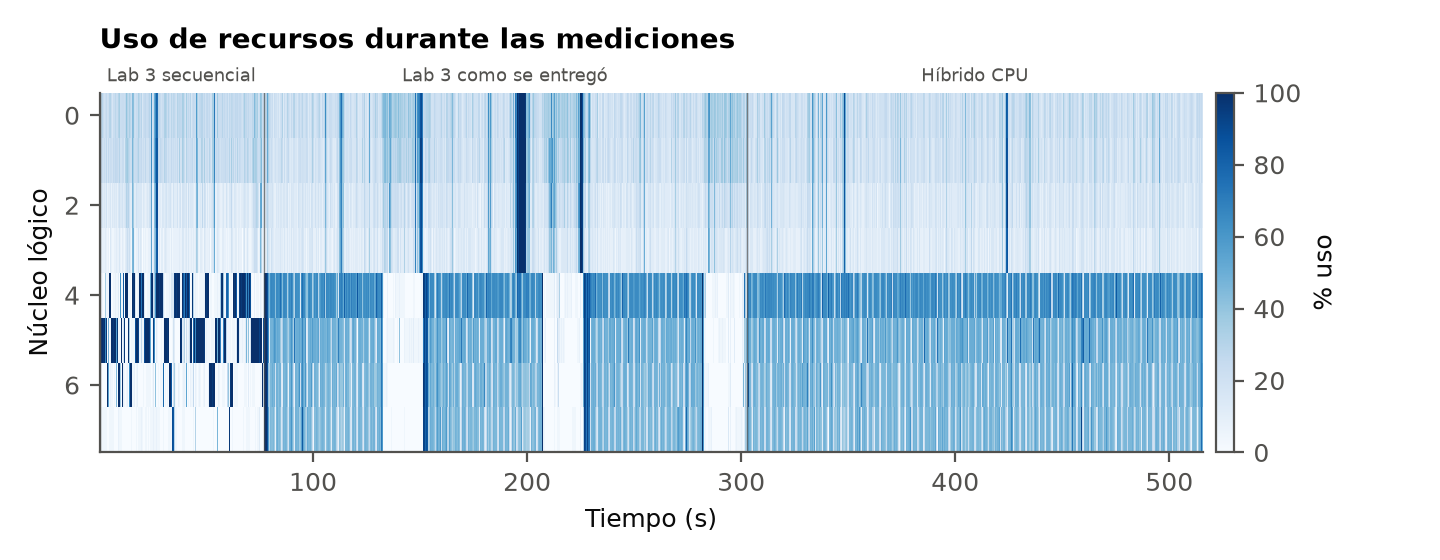

In [17]:
for carpeta in referencias_cpu:
    tabla(carpeta, "fases", f"Resumen por fase en {carpeta.name}")
    tabla(carpeta, "prep", f"Decodificación en {carpeta.name}")
    figura(carpeta, "monitor_bench")

## 8. Datos nuevos

El modelo se probó con el test interno (11,600 imágenes que nunca vio), con un dataset externo de 870 fotos
de otras manos y fondos (una mitad para elegir el modelo y otra para reportar).

In [18]:
for carpeta in [oficial, *referencias_cpu]:
    if carpeta:
        tabla(carpeta, "evaluacion", f"Evaluación ({carpeta.name})")
if oficial and (oficial / "eval" / "seleccion_modelo.json").exists():
    print(json.dumps(json.loads((oficial / "eval" / "seleccion_modelo.json").read_text()), indent=2, ensure_ascii=False))

**Evaluación (adrian-rtx3050)** (`results\adrian-rtx3050\tablas\evaluacion.md`)

| Conjunto | Imágenes | Exactitud | Macro F1 | Top-3 |
|---|---:|---:|---:|---:|
| base_external_final | 435 | 0.389 | 0.380 | 0.634 |
| base_external | 870 | 0.390 | 0.383 | 0.629 |
| base_external_seleccion | 435 | 0.391 | 0.385 | 0.623 |
| base_test | 11,600 | 0.954 | 0.952 | 0.999 |
| robusto_external_final | 435 | 0.526 | 0.504 | 0.731 |
| robusto_external | 870 | 0.533 | 0.510 | 0.726 |
| robusto_external_seleccion | 435 | 0.540 | 0.514 | 0.722 |
| robusto_test | 11,600 | 0.982 | 0.982 | 0.999 |


{
  "elegido": "robusto",
  "criterio": "macro F1 en external_seleccion (435 fotos)",
  "candidatos": {
    "base": {
      "macro_f1": 0.3851612158540373,
      "accuracy": 0.39080459770114945,
      "checkpoint": "results/adrian-rtx3050/train/base-cuda/model.pt"
    },
    "robusto": {
      "macro_f1": 0.5143721236905148,
      "accuracy": 0.5402298850574713,
      "checkpoint": "results/adrian-rtx3050/train/robusto-cuda/model.pt"
    }
  }
}


## 9. Conclusiones

El tiempo del Lab 3 tenía dos causas distintas y cada una tuvo su solución en un procesador diferente. La
preparación de archivos era trabajo repetido: decodificar los mismos JPEG en cada época. Ahora se hace una
sola vez, repartida entre los procesos del CPU, y queda en una caché `uint8`. La transformación de entrada y
la red son aritmética regular sobre tensores, y eso es lo que pasó a la GPU: un kernel propio en Numba CUDA,
con un hilo por píxel, y el entrenamiento con cuDNN en precisión mixta. Las dos fases se comunican con
copias asíncronas de `uint8`, cinco veces más pequeñas que el tensor de entrada, y se traslapan gracias a
dos buffers alternados. Los números de cada fase y el speedup total están en la sección 7 y en el informe.